In [1]:
import pandas as pd
import matplotlib.pyplot as plt 
import seaborn as sns 

In [2]:
df = pd.read_csv('Automobile.csv')

<Axes: xlabel='engine_size', ylabel='horsepower'>

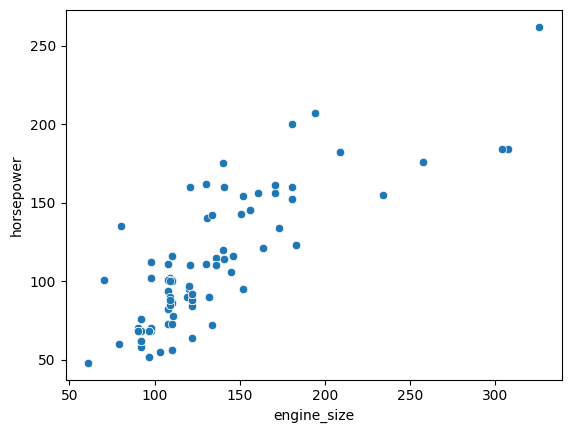

In [5]:
sns.scatterplot(data=df,x='engine_size',y='horsepower')

<Axes: xlabel='engine_size', ylabel='horsepower'>

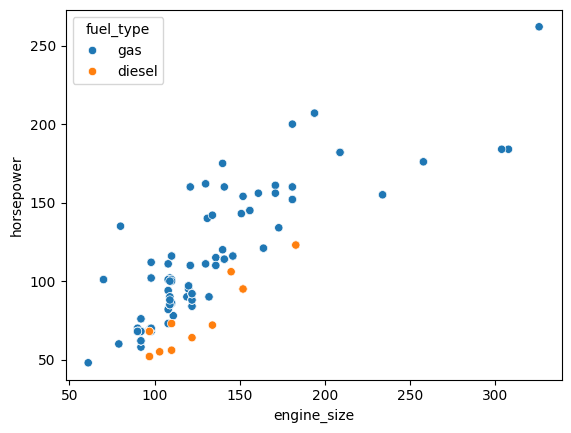

In [6]:
sns.scatterplot(data=df,x='engine_size',y='horsepower',hue='fuel_type')

Correlation

Correlation means association more precisely,it expresses the extent to which two variables change together at a constant rate.
* in a scatter plot when the y variable tends to increase as the x variables increase,we say there is a positive correlation between the variables 
* Again when y variable tends to decrease and x increase negative correlation 
* if points on the scatter plot seem to be scattered randomly we say that there is no correlation between the variables  

<Axes: xlabel='curb_weight', ylabel='engine_size'>

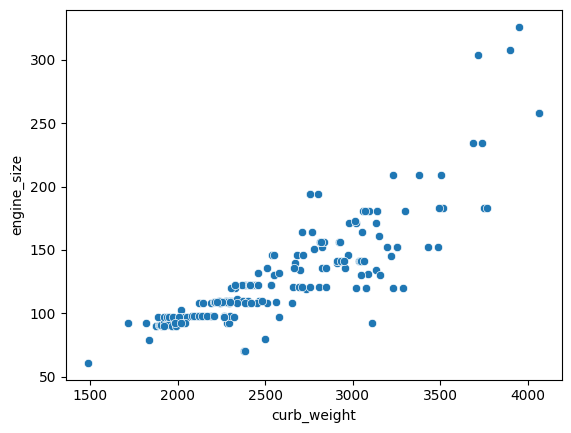

In [7]:
sns.scatterplot(data=df,x='curb_weight',y='engine_size')

<Axes: xlabel='bore', ylabel='stroke'>

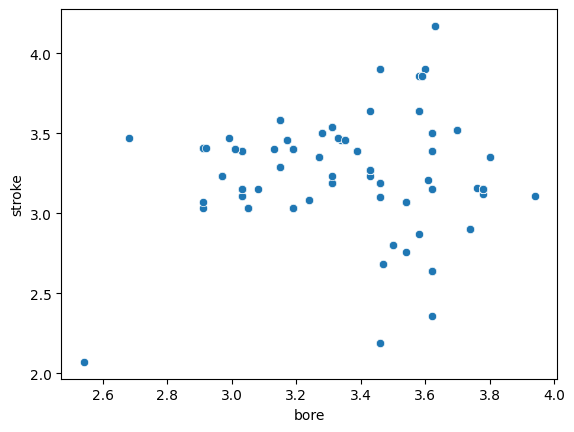

In [8]:
sns.scatterplot(data=df,x='bore',y='stroke')

* From the above plot, it is clear that the variables have no correlation

Pairplot
when many numeric col 
combination of scatterplot and individual histogram 



In [ ]:
df.columns

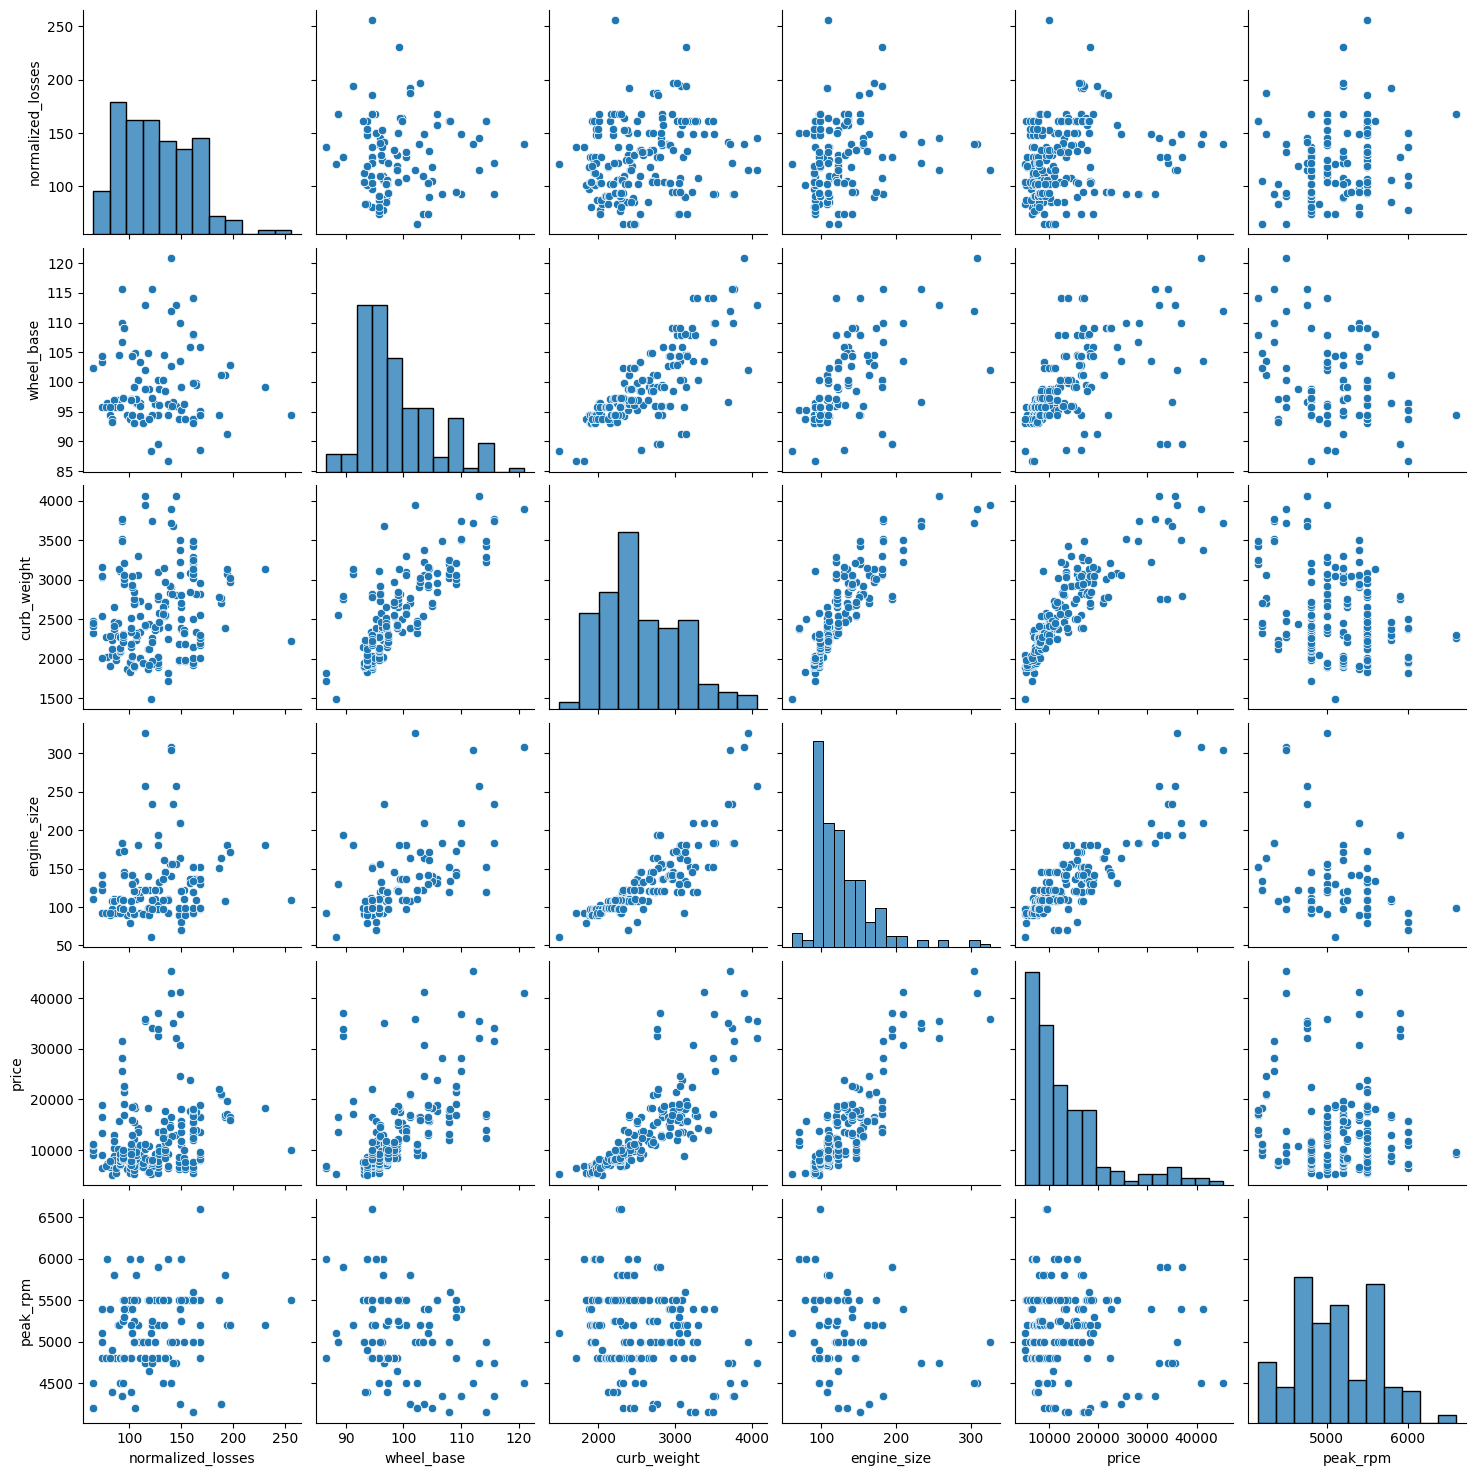

In [3]:
sns.pairplot(data=df[['normalized_losses','wheel_base','curb_weight','engine_size','price','peak_rpm']])

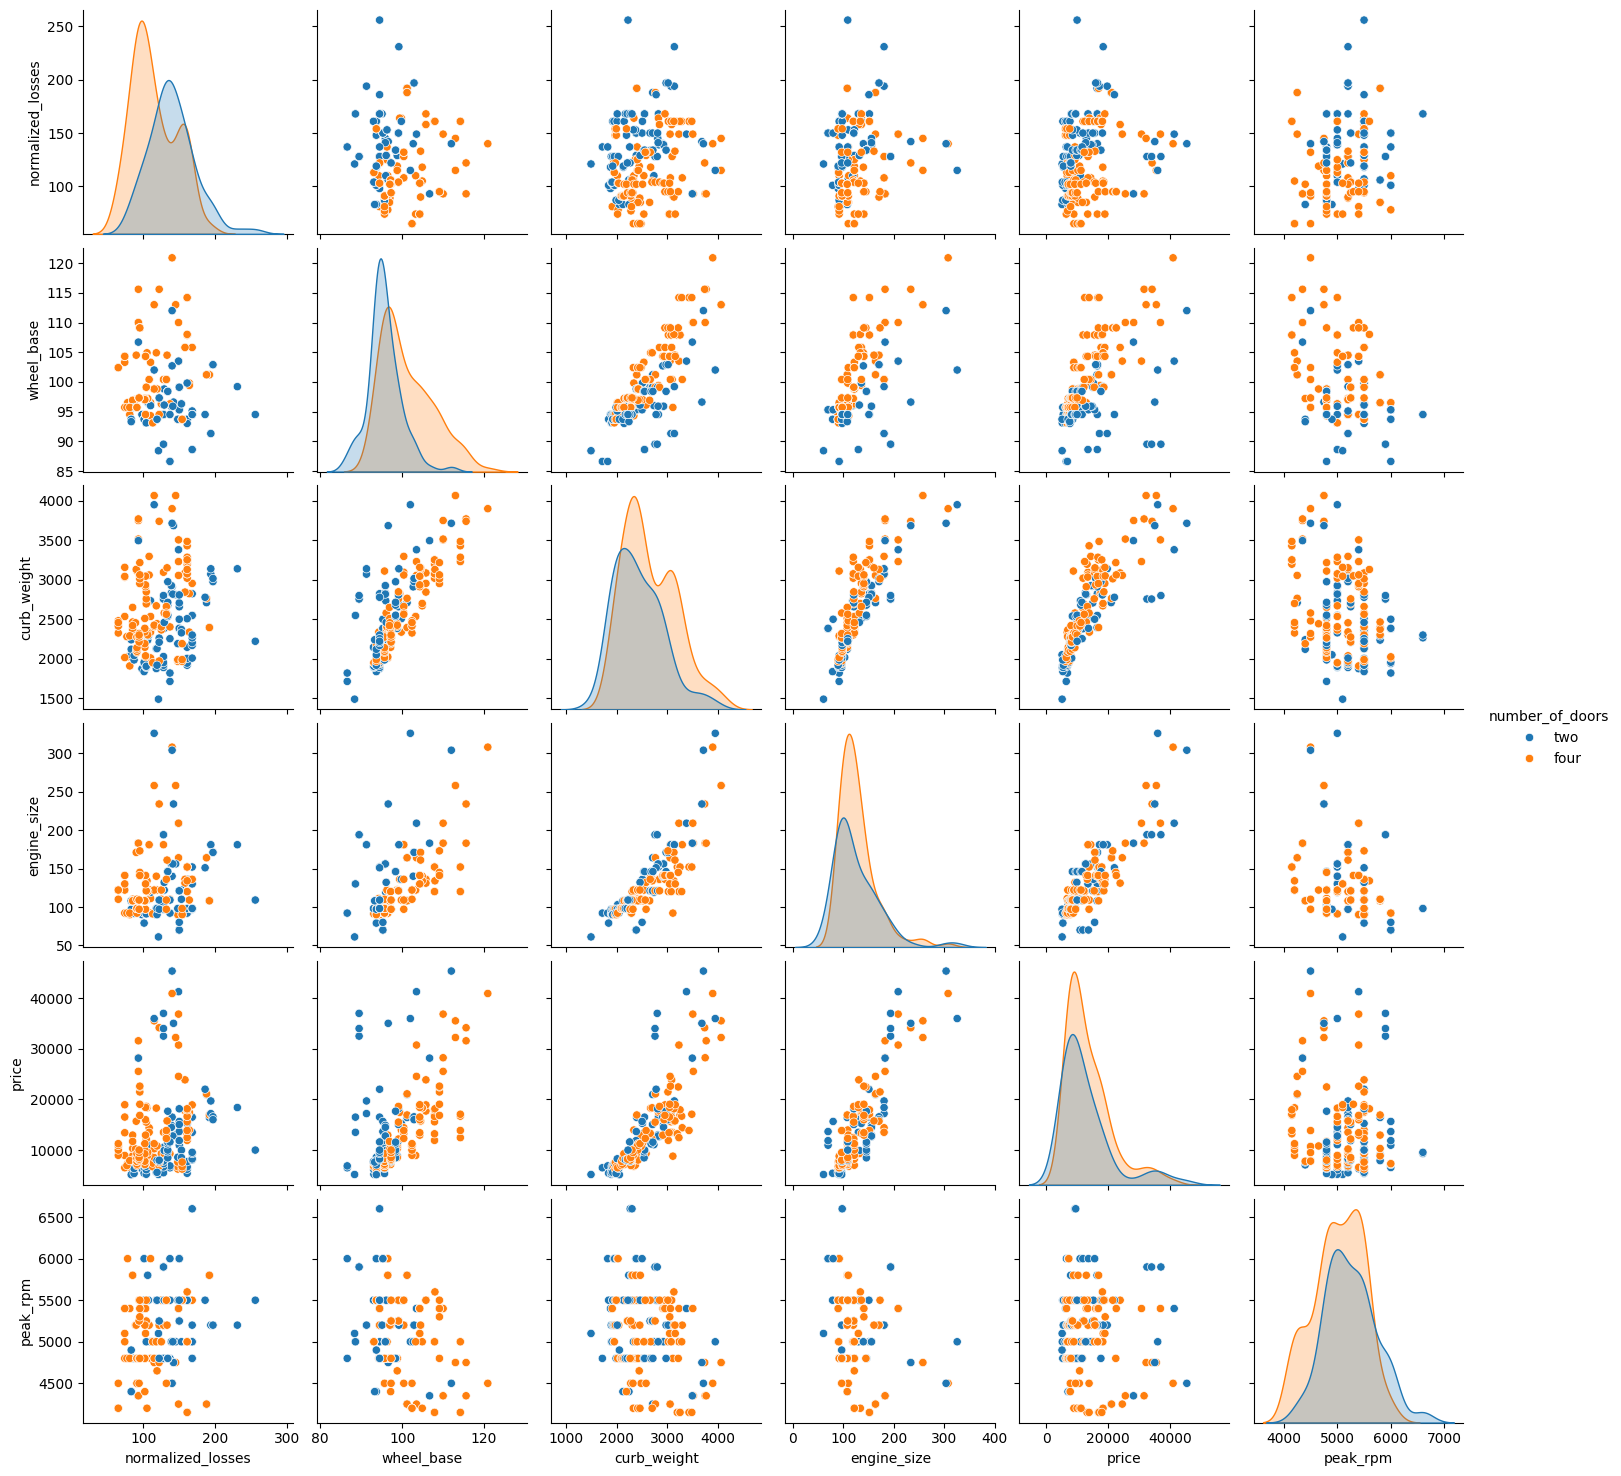

In [8]:
sns.pairplot(
    data=df,
    vars=['normalized_losses',
          'wheel_base',
          'curb_weight',
          'engine_size',
          'price',
          'peak_rpm'],
    hue='number_of_doors'
)

Heatmap

<Axes: >

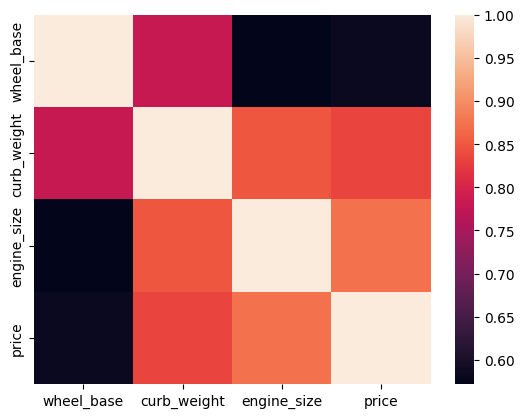

In [9]:
sns.heatmap(data=df[['wheel_base','curb_weight','engine_size','price']].corr())

We can set the annot parameter to True for displaying the numeric value in each cell
* To remove the color bar, the cbar parameter can be set to False

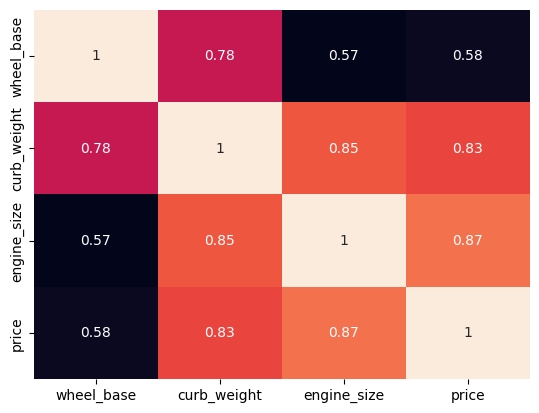

In [10]:
sns.heatmap(data=df[['wheel_base','curb_weight','engine_size','price']].corr(),annot=True,cbar=False);

Ploty 
* Ploty is an open-source Python graphing libarary for building interactive visualization 

In [12]:
%pip install Ploty 

Note: you may need to restart the kernel to use updated packages.


ERROR: Could not find a version that satisfies the requirement Ploty (from versions: none)
ERROR: No matching distribution found for Ploty


Bivariate Analysis

In [13]:
df = pd.read_csv('Melbourne_Housing.csv')

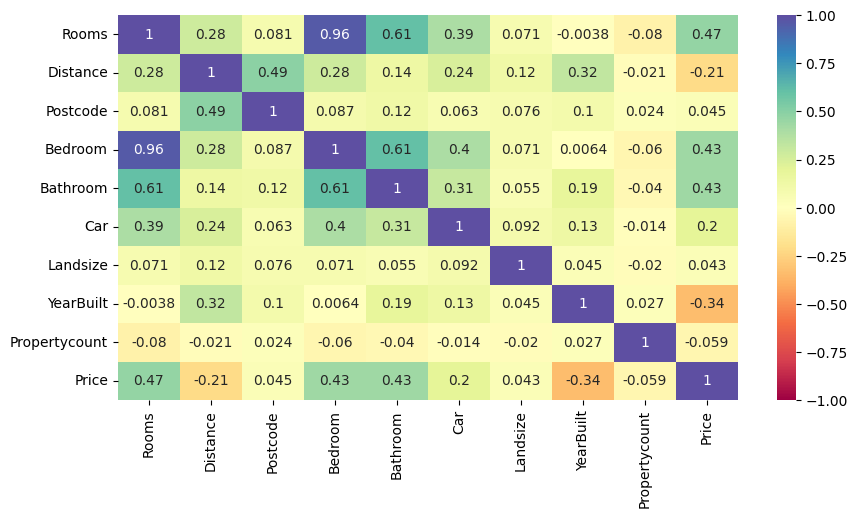

In [18]:
plt.figure(figsize=(10,5))

corr = df.corr(numeric_only=True)

sns.heatmap(corr, annot=True, cmap='Spectral', vmin=-1, vmax=1)
plt.show()

Observation

* Price column shows a high correlation with number of rooms,bedrooms,bathrooms and car parking spaces.This indicates that more the number of rooms,bedrooms,etc more will be the selling price of a propertly
* Price has a negative correlation with YearBuilt column.This indicates that distance incr selling price of properties decr 

In [19]:
# let's create a column with a sum of number of rooms,bedrooms,bathrooms, and car parking spaces 
df['Total Space'] = df['Rooms']+df['Bedroom']+df['Bathroom']+df['Car']
df.head()

,Suburb,Rooms,Type,SellerG,Date,Distance,Postcode,Bedroom,Bathroom,Car,Landsize,BuildingArea,YearBuilt,Regionname,Propertycount,Price,Total Space
0,Airport West,3,t,Nelson,03-09-2016,13.5,3042.0,3.0,2.0,1.0,303.0,225,2016.0,Western Metropolitan,3464,840000,9.0
1,Albert Park,2,h,hockingstuart,03-09-2016,3.3,3206.0,2.0,1.0,0.0,120.0,82,1900.0,Southern Metropolitan,3280,1275000,5.0
2,Albert Park,2,h,Thomson,03-09-2016,3.3,3206.0,2.0,1.0,0.0,159.0,inf,NaN,Southern Metropolitan,3280,1455000,5.0
3,Alphington,4,h,Brace,03-09-2016,6.4,3078.0,3.0,2.0,4.0,853.0,263,1930.0,Northern Metropolitan,2211,2000000,13.0
4,Alphington,3,h,Jellis,03-09-2016,6.4,3078.0,3.0,2.0,2.0,208.0,inf,2013.0,Northern Metropolitan,2211,1110000,10.0


* The column has been successfully added in the data frame

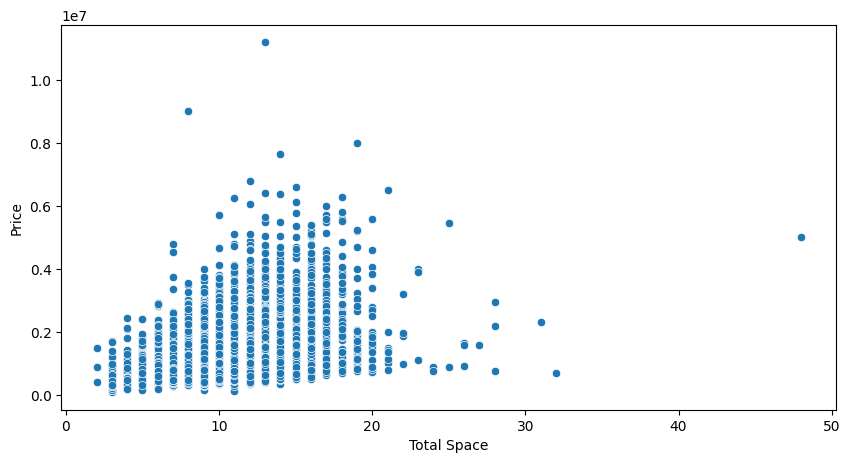

In [20]:
plt.figure(figsize=(10,5))
sns.scatterplot(data=df,x='Total Space',y='Price')
plt.show()

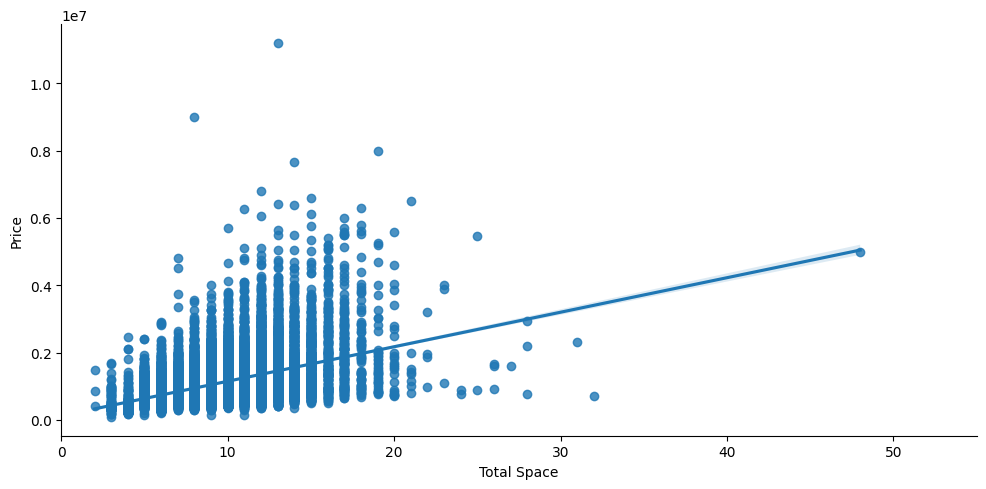

In [23]:
sns.lmplot(data=df,x='Total Space',y='Price',height=5,aspect=2)
plt.xlim(0,55)
plt.show()

In [24]:
# let's check the correlation between Total space and Price
df[['Total Space','Price']].corr()

,Total Space,Price
Total Space,1.000000,0.458282
Price,0.458282,1.000000


* As expected there is a positive correlation between Total Space and Price but it is not very high.

The distance of the property from the key facilities play a crucial role in deciding the selling price of property. The properties located closer to key facilities tend to be priced higher and vice versa.Let's find out if the same relationship exits in our data

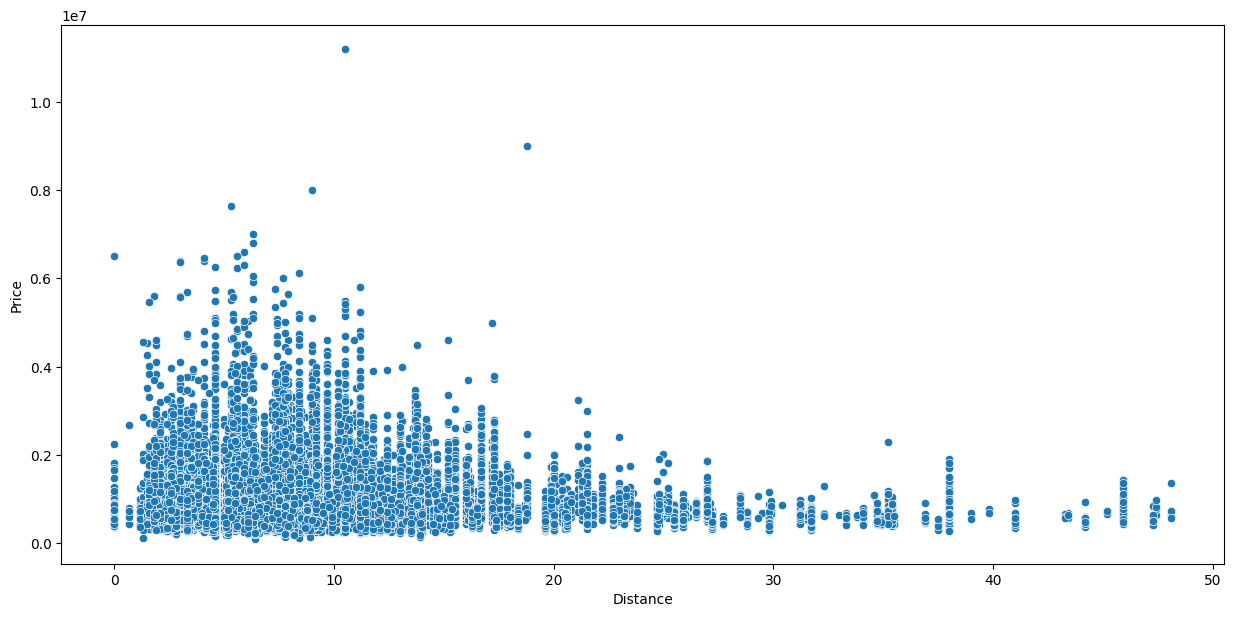

In [25]:
plt.figure(figsize=(15,7))
sns.scatterplot(data=df,x='Distance',y='Price')
plt.show()

C:\Users\hp\AppData\Local\Temp\ipykernel_11948\2698425900.py:2: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.lineplot(data=df,x='Distance',y='Price',ci=None)


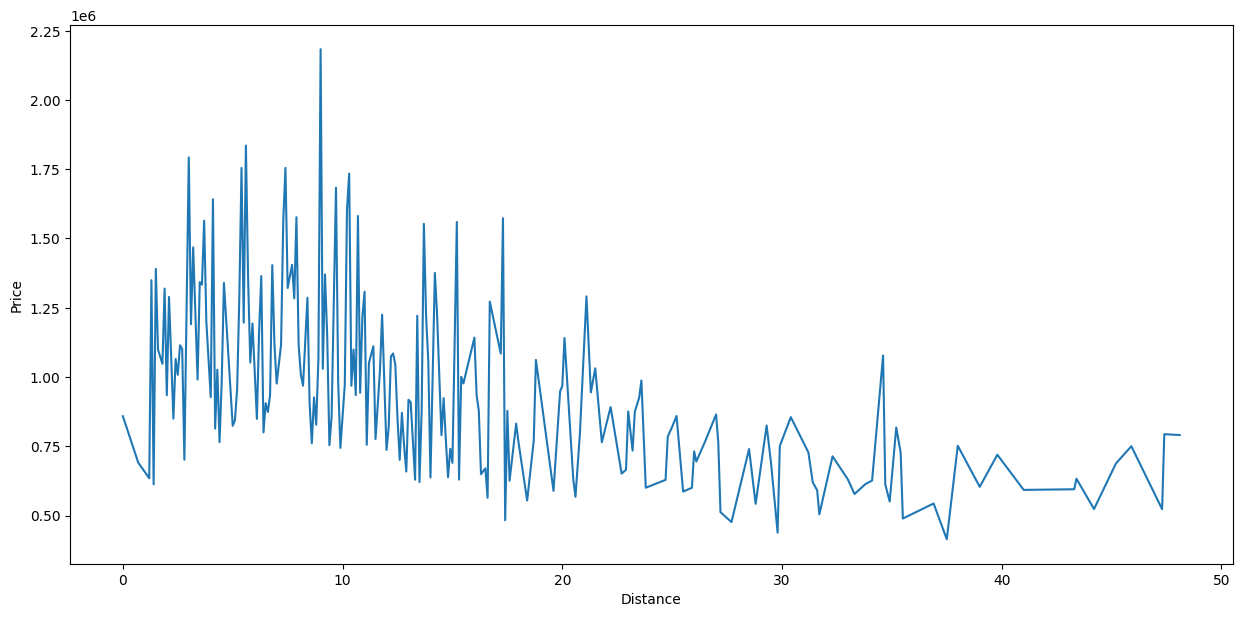

In [27]:
plt.figure(figsize=(15,7))
sns.lineplot(data=df,x='Distance',y='Price',ci=None)
plt.show()

Creating bins for distance column
* 0-15 KMs - The property will be said to be in Nearby location.
* 15-30 KMs - The property will be said to be in Moderately Close location.
* 30-50 KMs - The property will be said to be in Far away location
We will use pd.cut() functionto create the bins in Distance column

Syntax: pd.cut(x,bins,labels=Name,right=False)

x-column/array to be binned

bin - number of bins to create or an input of list for the range of bins
labels = specifies the labels for bins

right -if set to False, it excludes the rightmost edge of the interval


In [3]:
# using pd.cut() function to create bins
df['Distance_bins'] = pd.cut(df['Distance'],bins=[0,15,30,50],labels=['Nearby','Moderately Close','Far'],right=False)

KeyError: 'Distance'

In [ ]:
sns.boxplot(data=df,x='Distance_bins',y='Price')
plt.show()